# LM6 Lab — Sequences, Series and the Time Value of Money

Companion notebook to **From Calculus to Kelly, LM6**. It rebuilds every exhibit and computational example of the module from the bundled data and solves the computational practice problems.

| Part | Rebuilds |
|:--|:--|
| 1 | Geometric series, annuities, perpetuities (Exhibits 2–4, Examples 1–3) |
| 2 | Gordon growth model on 0050 from raw prices and dividends (Exhibit 5, Examples 4–5) |
| 3 | Bond pricing, bisection for yield to maturity and IRR, pull to par (Exhibits 6–7, Examples 6–7) |
| 4 | Loan amortization: level payment, equal principal, grace period (Exhibit 8, Example 8) |
| 5 | Implied forward rates and covered interest parity (Exhibit 9, Example 9) |
| 6 | The TX basis through the 2025 dividend season (Exhibits 1 and 10–14, Example 10) |
| 7 | Practice-problem solutions and an extension exercise |

**Data** (`data/`, retrieved 2026-10-10 from FinMind): TX regular-session settlements `TaiwanFuturesDaily` (2025-04-01 → 2025-10-31), TAIEX closes `TaiwanStockPrice` and the TWSE total-return index `TaiwanStockTotalReturnIndex` for calendar 2025, TAIEX high/low around 27 June 2025, 0050 daily closes 2014-10-31 → 2026-10-09 and cash dividends `TaiwanStockDividendResult`.

**Environment.** `uv pip install polars pyarrow numpy matplotlib` (plus `requests` only for the optional live refresh in Part 7).

In [1]:
from pathlib import Path
import datetime as dt
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(12)
pl.Config.set_float_precision(4)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Geometric series and annuities

Everything rests on (6.2): $\sum_{k=0}^{n-1}ax^k=a(1-x^n)/(1-x)$, and on (6.3) for $|x|<1$. With $v=1/(1+i)$ the annuity factors follow: $a_{n,i}=(1-v^n)/i$ (6.5), $s_{n,i}=((1+i)^n-1)/i$ (6.6), and an annuity due is worth $1+i$ times as much (6.7).

In [2]:
def geo_sum(a, x, n):
    return n * a if x == 1 else a * (1 - x**n) / (1 - x)                # eq. (6.2)

def annuity_pv(A, i, n, due=False):
    pv = A * n if i == 0 else A * (1 - (1 + i) ** -n) / i              # eq. (6.5)
    return pv * (1 + i) if due else pv                                 # eq. (6.7)

def annuity_fv(A, i, n, due=False):
    fv = A * n if i == 0 else A * ((1 + i) ** n - 1) / i               # eq. (6.6)
    return fv * (1 + i) if due else fv

def growing_annuity_pv(A1, i, g, n):
    return n * A1 / (1 + i) if abs(i - g) < 1e-15 else A1 / (i - g) * (1 - ((1 + g) / (1 + i)) ** n)   # eq. (6.9)

def bisect(f, a, b, tol=1e-10, log=None):
    fa = f(a)
    if fa * f(b) > 0:
        raise ValueError("root not bracketed")
    k = 0
    while True:
        k += 1
        m = 0.5 * (a + b); fm = f(m)
        if log is not None: log.append((k, a, b, m, fm))
        if fm == 0 or (b - a) / 2 < tol: return m, k
        if fa * fm < 0: b = m
        else: a, fa = m, fm

# Example 1: share of a perpetuity paid within n years, 1 - v^n
tail = pl.DataFrame({"rate": [0.02, 0.05, 0.08]}).with_columns(
    (1 / pl.col("rate")).alias("value of 1/yr forever"),
    *[(1 - (1 + pl.col("rate")) ** -n).alias(f"within {n}y") for n in (10, 30, 50)])
tail

rate,value of 1/yr forever,within 10y,within 30y,within 50y
f64,f64,f64,f64,f64
0.0200,50.0000,0.1797,0.4479,0.6285
0.0500,20.0000,0.3861,0.7686,0.9128
0.0800,12.5000,0.5368,0.9006,0.9787


In [3]:
# Knowledge check (Section 2) and the sum in Practice Problem 1
print("52-week challenge:", sum(100 * k for k in range(1, 53)), "| 95% forever from 100:", round(100 / (1 - 0.95), 2))
print("PP1: sum 0.9^k, k<20 =", round(geo_sum(1, 0.9, 20), 4))

# Example 2(a): monthly deposit for NT$3,000,000 in 8 years at 0.2% a month; (b) how long NT$10m lasts at 0.25%
i, n = 0.002, 96
A = 3_000_000 * i / ((1 + i) ** n - 1)
print(f"Ex2(a) deposit {A:,.2f}  total {A*n:,.0f}  interest {3_000_000-A*n:,.0f}  as annuity due {A/(1+i):,.2f}")
nmon = -math.log(1 - 10_000_000 * 0.0025 / 60_000) / math.log(1.0025)
print(f"Ex2(b) lasts {nmon:.2f} months = {nmon/12:.2f} years;  perpetual withdrawal {10_000_000*0.0025:,.0f}")

# Example 3: rent in advance (annuity due) and the implied return of prepaying
i = 0.02 / 12
print(f"Ex3 PV due {annuity_pv(30_000, i, 12, True):,.0f}  ordinary {annuity_pv(30_000, i, 12):,.0f}")
im, _ = bisect(lambda x: annuity_pv(30_000, x, 12, True) - 350_000, 1e-6, 0.05)
print(f"    implied monthly {im:.4%}  nominal {12*im:.2%}  effective {(1+im)**12-1:.2%}")

# Knowledge check (Section 3)
print("KC3:", [round(f(1000, 0.03, 10, d), 2) for f in (annuity_pv, annuity_fv) for d in (False, True)])
# Section 4 checks: perpetuity, deferred perpetuity, growing annuity
print("perpetuity 2.4/4%:", 2.4 / 0.04, " deferred m=5:", round(2.4 / 0.04 / 1.04**5, 2), " due:", round(2.4 / 0.04 * 1.04, 2))
print("growing annuity (6.9):", round(growing_annuity_pv(1, 0.05, 0.03, 20), 4),
      " direct sum:", round(sum(1.03 ** (t - 1) / 1.05**t for t in range(1, 21)), 4),
      " g = i:", round(growing_annuity_pv(1, 0.05, 0.05, 20), 4))

52-week challenge: 137800 | 95% forever from 100: 2000.0
PP1: sum 0.9^k, k<20 = 8.7842
Ex2(a) deposit 28,377.08  total 2,724,200  interest 275,800  as annuity due 28,320.44
Ex2(b) lasts 215.87 months = 17.99 years;  perpetual withdrawal 25,000
Ex3 PV due 356,724  ordinary 356,130
    implied monthly 0.5164%  nominal 6.20%  effective 6.38%
KC3: [8530.2, 8786.11, 11463.88, 11807.8]
perpetuity 2.4/4%: 60.0  deferred m=5: 49.32  due: 62.4
growing annuity (6.9): 15.9648  direct sum: 15.9648  g = i: 19.0476


## Part 2 — The Gordon model on 0050

$P_0=D_1/(k-g)$ (6.11) implies $k=D_1/P_0+g$ (6.12) and $g=(kP_0-D_0)/(P_0+D_0)$ (6.13). Inputs come from the raw closes and the dividend file; 0050 split 4-for-1 on 2025-06-18, so earlier prices and dividends are divided by 4. The checksum confirms every close against FinMind's own `spread` column, except on ex-dividend and split days.

In [4]:
px = pl.read_csv(DATA / "0050_daily_raw.csv").sort("date")
div = pl.read_csv(DATA / "0050_dividends.csv")
chk = px.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap")).filter(pl.col("gap") > 0.005)
print("checksum mismatches:", chk.height, "| unexplained:", sorted(set(chk["date"]) - set(div["date"]) - {"2025-06-18"}))

SPLIT = "2025-06-18"
def close_on(d):
    return px.filter(pl.col("date") == pl.lit(d))["close"][0]

def ttm_dividends(end, start):
    x = div.filter((pl.col("date") > pl.lit(start)) & (pl.col("date") <= pl.lit(end)))
    return x.select(pl.when(pl.col("date") < pl.lit(SPLIT)).then(pl.col("cash_dividend") / 4)
                      .otherwise(pl.col("cash_dividend")).sum()).item()

P_new, D_new = close_on("2026-10-08"), ttm_dividends("2026-10-08", "2025-10-08")
P_old, D_old = close_on("2016-10-07") / 4, ttm_dividends("2016-10-07", "2015-10-07")
g_div = (D_new / D_old) ** (1 / 10) - 1
g_px = (P_new / P_old) ** (1 / 10) - 1
k_imp = D_new * (1 + g_div) / P_new + g_div
implied_g = lambda k, P, D: (k * P - D) / (P + D)
ex5 = pl.DataFrame({"": ["price (split-adjusted)", "TTM dividends", "dividend yield", "implied g at k=8%", "implied g at k=10%"],
                    "2016-10-07": [P_old, D_old, D_old / P_old, implied_g(0.08, P_old, D_old), implied_g(0.10, P_old, D_old)],
                    "2026-10-08": [P_new, D_new, D_new / P_new, implied_g(0.08, P_new, D_new), implied_g(0.10, P_new, D_new)]})
print(f"dividend CAGR {g_div:.2%}  price CAGR {g_px:.2%}  implied k {D_new*(1+g_div)/P_new:.2%} + {g_div:.2%} = {k_imp:.2%}")
print(f"share of value after year 30: {((1+g_div)/(1+k_imp))**30:.2f}  (k=9%, g=4%: {(1.04/1.09)**30:.2f})")
D1 = D_new * (1 + g_div)
print(f"price if k-g -0.5pt: {D1/(k_imp-g_div-0.005):.2f}   +0.5pt: {D1/(k_imp-g_div+0.005):.2f}")
ex5   # Exhibit 5

checksum mismatches: 23 | unexplained: []
dividend CAGR 8.43%  price CAGR 20.43%  implied k 1.51% + 8.43% = 9.94%
share of value after year 30: 0.66  (k=9%, g=4%: 0.24)
price if k-g -0.5pt: 171.90   +0.5pt: 86.34


,2016-10-07,2026-10-08
str,f64,f64
"""price (split-adjusted)""",17.9125,114.9500
"""TTM dividends""",0.7125,1.6000
"""dividend yield""",0.0398,0.0139
"""implied g at k=8%""",0.0387,0.0652
"""implied g at k=10%""",0.0579,0.0849


In [5]:
# Example 4: two-stage dividend model (illustrative)
D0, g1, g2, k, N = 10.0, 0.12, 0.04, 0.09, 5
divs = [D0 * (1 + g1) ** t for t in range(1, N + 1)]
pv1 = sum(d / (1 + k) ** t for t, d in enumerate(divs, 1))
P5 = divs[-1] * (1 + g2) / (k - g2)
print([round(d, 4) for d in divs], f"stage 1 {pv1:.4f} (formula {growing_annuity_pv(D0*(1+g1), k, g1, N):.4f})")
print(f"P5 {P5:.4f}  PV(P5) {P5/(1+k)**N:.4f}  P0 {pv1 + P5/(1+k)**N:.2f}  terminal share {P5/(1+k)**N/(pv1 + P5/(1+k)**N):.1%}")
print("KC4: k =", 3 / 62.5, " price with 1% growth:", round(3 / (3 / 62.5 - 0.01), 2))

[11.2, 12.544, 14.0493, 15.7352, 17.6234] stage 1 54.2831 (formula 54.2831)
P5 366.5671  PV(P5) 238.2434  P0 292.53  terminal share 81.4%
KC4: k = 0.048  price with 1% growth: 78.95


## Part 3 — Bonds, yield to maturity and IRR

$P=C\,a_{n,y}+F(1+y)^{-n}$ (6.14) and $P-F=(C-yF)\,a_{n,y}$ (6.15). The price is strictly decreasing in $y$, so bisection on a sign-changing bracket always converges, halving the error at every step.

In [6]:
def bond_price(y, c, n, F=100.0):
    return annuity_pv(c * F, y, n) + F * (1 + y) ** -n

def amort_payment(L, i, n):
    return L * i / (1 - (1 + i) ** -n)                                # eq. (6.16)

zero = 100 / 1.02**5; coup = bond_price(0.02, 0.03, 5); A5 = amort_payment(100, 0.03, 5)
print(f"Ex6: zero {zero:.4f}  coupon {coup:.4f}  amortizing payment {A5:.4f} price {annuity_pv(A5, 0.02, 5):.4f}")
print(f"     premium by (6.15): {(3 - 2) * annuity_pv(1, 0.02, 5):.4f}")

log = []
ytm, k = bisect(lambda y: bond_price(y, 0.015, 10) - 97.20, 0.0, 0.05, tol=1e-8, log=log)
ex6 = pl.DataFrame(log, schema=["step", "a", "b", "mid", "P(mid)-97.20"], orient="row")
print(f"YTM {ytm:.6%} after {k} steps; P(0) = {bond_price(0, 0.015, 10):.2f}, P(5%) = {bond_price(0.05, 0.015, 10):.2f}")
ex6.head(8)   # Exhibit 6

Ex6: zero 90.5731  coupon 104.7135  amortizing payment 21.8355 price 102.9205
     premium by (6.15): 4.7135
YTM 1.808601% after 23 steps; P(0) = 115.00, P(5%) = 72.97


step,a,b,mid,P(mid)-97.20
i64,f64,f64,f64,f64
1,0.0000,0.0500,0.0250,-5.9521
2,0.0000,0.0250,0.0125,5.1364
3,0.0125,0.0250,0.0188,-0.5906
4,0.0125,0.0188,0.0156,2.2255
5,0.0156,0.0188,0.0172,0.8058
6,0.0172,0.0188,0.0180,0.1047
7,0.0180,0.0188,0.0184,-0.2437
8,0.0180,0.0184,0.0182,-0.0696


In [7]:
# Example 7: IRR of a savings policy (pay 100,000 at t=0..5, receive 700,000 at t=10)
flows = pl.DataFrame({"t": list(range(6)) + [10], "cf": [-100_000] * 6 + [700_000]})
npv = lambda y: flows.select((pl.col("cf") * (1 + y) ** (-pl.col("t"))).sum()).item()
lg = []
irr, k = bisect(npv, 0.0, 0.10, tol=1e-8, log=lg)
print(f"IRR {irr:.4%} after {k} steps; first trials:", [(f"{m:.4%}", round(f)) for _, _, _, m, f in lg[:5]])
print(f"NPV at 1.7%: {npv(0.017):,.0f};  premiums grown at 1.7% to t=10: {sum(100_000 * 1.017**(10 - t) for t in range(6)):,.0f}")

# Deep dive: two IRRs when the cash flows change sign twice
roots = np.roots([-132, 230, -100])        # -132 v^2 + 230 v - 100 = 0
print("IRRs:", sorted(f"{1/v - 1:.2%}" for v in roots))
print("KC5: 3y 2% coupon at 2.5% =", round(bond_price(0.025, 0.02, 3), 4))

IRR 2.0683% after 24 steps; first trials: [('5.0000%', -103208), ('2.5000%', -17744), ('1.2500%', 36443), ('1.8750%', 8268), ('2.1875%', -4998)]
NPV at 1.7%: 15,932;  premiums grown at 1.7% to t=10: 681,143
IRRs: ['10.00%', '20.00%']
KC5: 3y 2% coupon at 2.5% = 98.572


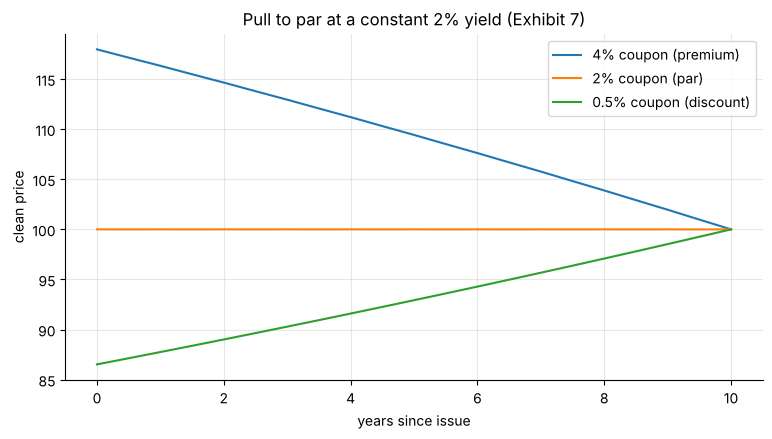

{0.04: (117.97, 109.43), 0.005: (86.53, 92.93)}


In [8]:
# Exhibit 7: pull to par, clean prices monthly at a constant 2% yield
def clean_price(t, c, y=0.02, n=10, F=100.0):
    if t >= n: return F
    full = sum((c * F + (F if j == n else 0.0)) * (1 + y) ** -(j - t) for j in range(1, n + 1) if j > t + 1e-12)
    return full - c * F * (t - int(t + 1e-12))

ts = np.arange(121) / 12
fig, ax = plt.subplots()
for c, lab in ((0.04, "4% coupon (premium)"), (0.02, "2% coupon (par)"), (0.005, "0.5% coupon (discount)")):
    ax.plot(ts, [clean_price(t, c) for t in ts], label=lab)
ax.set_xlabel("years since issue"); ax.set_ylabel("clean price"); ax.set_title("Pull to par at a constant 2% yield (Exhibit 7)"); ax.legend(); plt.show()
print({c: (round(clean_price(0, c), 2), round(clean_price(5, c), 2)) for c in (0.04, 0.005)})

## Part 4 — Loan amortization

Level payment: $A=Li/(1-(1+i)^{-n})$ (6.16), balance $B_k=A\,a_{n-k,i}$ (6.17), principal $P_k=Av^{n-k+1}$ (6.18). Equal principal: total interest $iL(n+1)/2$ (6.19). The schedules below are built row by row from the balance recurrence (6.4), so they test the closed forms.

In [9]:
def schedule(L, apr, years, grace_years=0, method="level"):
    i, n = apr / 12, years * 12
    m = grace_years * 12
    A, P = amort_payment(L, i, n - m), L / (n - m)
    rows, B = [], L
    for k in range(1, n + 1):
        I = B * i
        prin = 0.0 if k <= m else (A - I if method == "level" else P)
        B -= prin
        rows.append((k, I + prin, I, prin, B))
    return pl.DataFrame(rows, schema=["k", "payment", "interest", "principal", "balance"], orient="row")

lvl = schedule(10_000_000, 0.022, 30)
eqp = schedule(10_000_000, 0.022, 30, method="equal")
grc = schedule(10_000_000, 0.022, 30, grace_years=3)
i = 0.022 / 12
print(f"payment {lvl['payment'][0]:,.2f};  balance after 60 {lvl['balance'][59]:,.2f} (prospective {annuity_pv(lvl['payment'][0], i, 300):,.2f})")
print(f"interest in 5 years {lvl['interest'][:60].sum():,.0f}  principal {lvl['principal'][:60].sum():,.0f}")
print(f"principal ratio {lvl['principal'][1] / lvl['principal'][0]:.7f} = 1 + i;  doubling time {math.log(2)/math.log(1+i):.1f} months")
summary = pl.DataFrame({
    "method": ["level payment", "equal principal", "level after 3-year grace"],
    "first": [s["payment"][0] for s in (lvl, eqp, grc)],
    "payment 37": [s["payment"][36] for s in (lvl, eqp, grc)],
    "last": [s["payment"][-1] for s in (lvl, eqp, grc)],
    "total interest": [s["interest"].sum() for s in (lvl, eqp, grc)]})
print(f"equal-principal saving {summary['total interest'][0] - summary['total interest'][1]:,.0f};  grace cost {summary['total interest'][2] - summary['total interest'][0]:,.0f}")
print("equal-principal payment falls below the level payment at month", eqp.filter(pl.col("payment") < lvl["payment"][0])["k"][0])
lvl.filter(pl.col("k").is_in([1, 2, 120, 180, 240, 359, 360]))   # Exhibit 8, first table

payment 37,970.08;  balance after 60 8,755,754.89 (prospective 8,755,754.89)
interest in 5 years 1,033,960  principal 1,244,245
principal ratio 1.0018333 = 1 + i;  doubling time 378.4 months
equal-principal saving 360,064;  grace cost 261,984
equal-principal payment falls below the level payment at month 161


k,payment,interest,principal,balance
i64,f64,f64,f64,f64
1,37970.0841,18333.3333,19636.7508,9980363.2492
2,37970.0841,18297.3326,19672.7515,9960690.4977
120,37970.0841,13550.8825,24419.2017,7366971.2382
180,37970.0841,10714.2099,27255.8742,5816858.6195
240,37970.0841,7548.0134,30422.0707,4086676.1525
359,37970.0841,138.8417,37831.2424,37900.5997
360,37970.0841,69.4844,37900.5997,0.0000


In [10]:
summary   # Exhibit 8, second table

method,first,payment 37,last,total interest
str,f64,f64,f64,f64
"""level payment""",37970.0841,37970.0841,37970.0841,3669230.2915
"""equal principal""",46111.1111,44277.7778,27828.7037,3309166.6667
"""level after 3-year grace""",18333.3333,40960.5391,40960.5391,3931214.6749


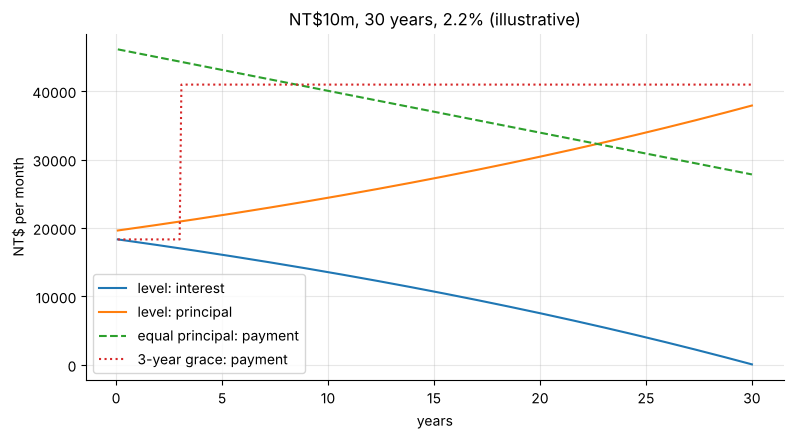

5%: doubling 166.7 months; crossover at payment 195
KC6: 26252.24 2798273


In [11]:
fig, ax = plt.subplots()
yrs = lvl["k"] / 12
ax.plot(yrs, lvl["interest"], label="level: interest"); ax.plot(yrs, lvl["principal"], label="level: principal")
ax.plot(yrs, eqp["payment"], "--", label="equal principal: payment"); ax.plot(yrs, grc["payment"], ":", label="3-year grace: payment")
ax.set_xlabel("years"); ax.set_ylabel("NT$ per month"); ax.set_title("NT$10m, 30 years, 2.2% (illustrative)"); ax.legend(); plt.show()
# 5% comparison: principal overtakes interest only when the remaining term is below the doubling time
i5 = 0.05 / 12
print("5%: doubling", round(math.log(2) / math.log(1 + i5), 1), "months; crossover at payment",
      schedule(10_000_000, 0.05, 30).filter(pl.col("principal") > pl.col("interest"))["k"][0])
print("KC6:", round(amort_payment(5_000_000, 0.002, 240), 2), round(schedule(5_000_000, 0.024, 20)["balance"][119]))

## Part 5 — Forward rates and covered interest parity

$(1+z_B)^B=(1+z_A)^A(1+f_{A,B-A})^{B-A}$ (6.20) and $F=S(1+i_{\text{TWD}}T)/(1+i_{\text{USD}}T)$ (6.21).

In [12]:
curve = pl.DataFrame({"t": [1, 2, 3, 4, 5], "z": [0.015, 0.017, 0.0185, 0.0195, 0.0205]}).with_columns(
    ((1 + pl.col("z")) ** (-pl.col("t"))).alias("discount factor"))
curve = curve.with_columns((pl.col("discount factor").shift(1).fill_null(1.0) / pl.col("discount factor") - 1).alias("f(t-1,1)"))
f23 = ((1.0205**5 / 1.017**2) ** (1 / 3)) - 1
P_curve = (3 * curve["discount factor"]).sum() + 100 * curve["discount factor"][-1]
y_curve, _ = bisect(lambda y: bond_price(y, 0.03, 5) - P_curve, 0.0, 0.1)
print(f"f(2,3) = {f23:.4%} (log approximation {(5*0.0205 - 2*0.017)/3:.4%});  5y 3% bond {P_curve:.4f}, YTM {y_curve:.4%}")
S, iT, iU = 30.00, 0.016, 0.040
F = S * (1 + iT) / (1 + iU)
print(f"USD/TWD forward {F:.4f}  points {F - S:+.4f}  first-order {S*(1 + iT - iU):.4f}  arbitrage at 29.50: {(29.50 - F) * (1 + iU):.4f} TWD")
curve   # Exhibit 9

f(2,3) = 2.2840% (log approximation 2.2833%);  5y 3% bond 104.5346, YTM 2.0369%
USD/TWD forward 29.3077  points -0.6923  first-order 29.2800  arbitrage at 29.50: 0.2000 TWD


t,z,discount factor,"f(t-1,1)"
i64,f64,f64,f64
1,0.0150,0.9852,0.0150
2,0.0170,0.9668,0.0190
3,0.0185,0.9465,0.0215
4,0.0195,0.9257,0.0225
5,0.0205,0.9035,0.0245


## Part 6 — The TX basis through the 2025 dividend season

Futures: regular-session settlement prices; the expiring contract shows settlement 0.0 on its expiry day (the final settlement price is not in the file) and is dropped. Expiry is the third Wednesday of the delivery month. The realized dividend yield over $[t,T]$ is $q\tau_{\text{real}}=\ln(TR_T/TR_t)-\ln(S_T/S_t)$, and the decomposition (6.25) is
$F-S=S(e^{r\tau}-1)-Se^{r\tau}(1-e^{-q_{\text{real}}\tau})+\varepsilon$.

In [13]:
R_PROXY = 0.02
idx = (pl.read_csv(DATA / "TAIEX_2025.csv").select("date", pl.col("close").alias("S"), "spread")
         .join(pl.read_csv(DATA / "TAIEX_TR_2025.csv").rename({"price": "TR"}), on="date", how="full", coalesce=True).sort("date"))
assert idx.null_count().sum_horizontal().item() == 0
spread_err = idx.select((pl.col("S") - pl.col("S").shift(1) - pl.col("spread")).abs().max()).item()
idx = idx.with_columns(((pl.col("TR") / pl.col("TR").shift(1)).log() - (pl.col("S") / pl.col("S").shift(1)).log()).alias("dq"))
print(f"{idx.height} days; max |close - prev - spread| = {spread_err:.1e}; min daily dq = {idx['dq'].min()*1e4:.4f} bp")

def third_wednesday(y, m):
    d = dt.date(y, m, 1)
    return d + dt.timedelta(days=(2 - d.weekday()) % 7 + 14)

tx = pl.read_csv(DATA / "TX__2025-04-01__2025-10-31.csv").with_columns(pl.col("contract_date").cast(pl.Utf8).alias("c"))
expiry = {c: third_wednesday(int(c[:4]), int(c[4:])).isoformat() for c in tx["c"].unique().to_list()}
print("rows with settlement 0 (expiry days):", tx.filter(pl.col("settlement_price") == 0).select("date", "c").rows())
d = (tx.filter(pl.col("settlement_price") > 0)
       .with_columns(pl.col("c").replace_strict(expiry).alias("expiry"), pl.col("settlement_price").alias("F"))
       .join(idx.select("date", "S", "TR"), on="date", how="left")
       .join(idx.select(pl.col("date").alias("expiry"), pl.col("S").alias("S_T"), pl.col("TR").alias("TR_T")), on="expiry", how="left")
       .with_columns(((pl.col("expiry").str.to_date() - pl.col("date").str.to_date()).dt.total_days()).alias("days"))
       .with_columns((pl.col("days") / 365).alias("tau")))
r = R_PROXY
d = (d.with_columns(
        (pl.col("F") - pl.col("S")).alias("basis"),
        (r * pl.col("tau") - (pl.col("F") / pl.col("S")).log()).alias("qtau_imp"),
        ((pl.col("TR_T") / pl.col("TR")).log() - (pl.col("S_T") / pl.col("S")).log()).alias("qtau_real"))
      .with_columns(
        (pl.col("S") * ((r * pl.col("tau")).exp() - 1)).alias("carry"),
        (pl.col("S") * (r * pl.col("tau")).exp() * (1 - (-pl.col("qtau_real")).exp())).alias("dividends"),
        (pl.col("S") * ((r * pl.col("tau") - pl.col("qtau_real")).exp() - 1)).alias("fair_basis"))
      .with_columns(
        (pl.col("basis") - pl.col("fair_basis")).alias("residual"),
        ((pl.col("qtau_real") + (pl.col("F") / pl.col("S")).log()) / pl.col("tau")).alias("r_implied"))
      .sort(["date", "days"]))
print(d.height, "contract-days")

244 days; max |close - prev - spread| = 3.5e-12; min daily dq = -0.0044 bp
rows with settlement 0 (expiry days): [('2025-04-16', '202504'), ('2025-05-21', '202505'), ('2025-06-18', '202506'), ('2025-07-16', '202507'), ('2025-08-20', '202508'), ('2025-09-17', '202509'), ('2025-10-15', '202510')]
869 contract-days


In [14]:
# Exhibit 1: the curve on 27 June 2025
snap = d.filter(pl.col("date") == pl.lit("2025-06-27"))
snap.select("c", "expiry", "days", "F", pl.col("basis").round(2), (pl.col("basis") / pl.col("S")).alias("basis %"), "qtau_imp")

c,expiry,days,F,basis,basis %,qtau_imp
str,str,i64,f64,f64,f64,f64
"""202507""","""2025-07-16""",19,22122.0000,-458.0800,-0.0203,0.0215
"""202508""","""2025-08-20""",54,21948.0000,-632.0800,-0.0280,0.0314
"""202509""","""2025-09-17""",82,21834.0000,-746.0800,-0.0330,0.0381
"""202512""","""2025-12-17""",173,21700.0000,-880.0800,-0.0390,0.0492
"""202603""","""2026-03-18""",264,21607.0000,-973.0800,-0.0431,0.0585
"""202606""","""2026-06-17""",355,21493.0000,-1087.0800,-0.0481,0.0688


2025 total 2.93%; June-September 2.44% (83%); July 1.08%
11 Dec 2025: 14.21 bp = 40.40 index points (published estimate 40.34)


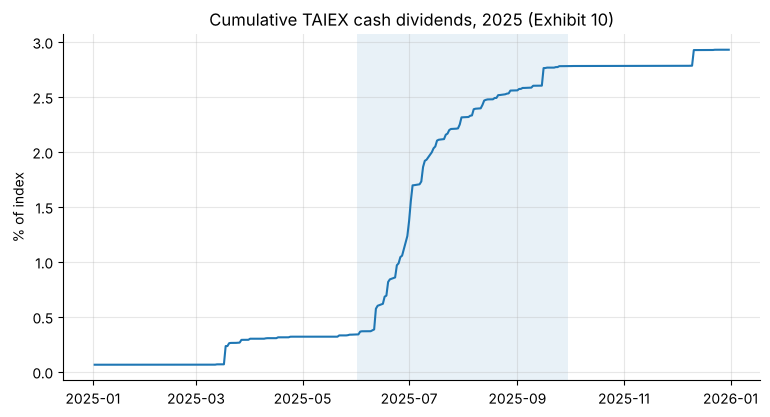

In [15]:
# Exhibit 10: dividends in calendar 2025
q2025 = math.log(idx["TR"][-1] / idx["TR"][0]) - math.log(idx["S"][-1] / idx["S"][0])
by_month = (idx.drop_nulls("dq").group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
               .agg(pl.col("dq").sum()).sort("month"))
jun_sep = by_month.filter(pl.col("month").is_between(6, 9))["dq"].sum()
dec11 = idx.filter(pl.col("date") == pl.lit("2025-12-11"))["dq"][0]
s_prev = idx.filter(pl.col("date") == pl.lit("2025-12-10"))["S"][0]
print(f"2025 total {q2025:.2%}; June-September {jun_sep:.2%} ({jun_sep/q2025:.0%}); July {by_month['dq'][6]:.2%}")
print(f"11 Dec 2025: {dec11*1e4:.2f} bp = {s_prev*(math.exp(dec11)-1):.2f} index points (published estimate 40.34)")
cum = idx.drop_nulls("dq").with_columns(pl.col("dq").cum_sum().alias("cum"), pl.col("date").str.to_date())
fig, ax = plt.subplots()
ax.plot(cum["date"], cum["cum"] * 100); ax.axvspan(dt.date(2025, 6, 1), dt.date(2025, 9, 30), alpha=0.1)
ax.set_ylabel("% of index"); ax.set_title("Cumulative TAIEX cash dividends, 2025 (Exhibit 10)"); plt.show()

In [16]:
# Exhibit 11: decomposition on 27 June 2025 (residual = basis - carry + dividends)
ex11 = snap.filter(pl.col("qtau_real").is_not_null()).select(
    "c", *[pl.col(x).round(2) for x in ("basis", "carry", "dividends", "residual")], "qtau_imp", "qtau_real", "r_implied")
check = ex11.select((pl.col("carry") - pl.col("dividends") + pl.col("residual") - pl.col("basis")).abs().max()).item()
print("adds up at 2 decimals:", check < 1e-9)
ex11

adds up at 2 decimals: True


c,basis,carry,dividends,residual,qtau_imp,qtau_real,r_implied
str,f64,f64,f64,f64,f64,f64,f64
"""202507""",-458.0800,23.5200,223.3400,-258.2600,0.0215,0.0099,-0.2030
"""202508""",-632.0800,66.9100,322.5500,-376.4400,0.0314,0.0143,-0.0949
"""202509""",-746.0800,101.6800,383.7900,-463.9700,0.0381,0.0171,-0.0736
"""202512""",-880.0800,215.0600,422.2400,-672.9000,0.0492,0.0187,-0.0444


In [17]:
# Robustness: average of 23-27 June, and calendar spreads (no index involved)
wk = (d.filter(pl.col("date").is_between(pl.lit("2025-06-23"), pl.lit("2025-06-27")) & pl.col("c").is_in(ex11["c"].to_list()))
       .group_by("c").agg(pl.col("basis").mean(), pl.col("residual").mean()).sort("c"))
print(wk)
sn = snap.sort("days")
for a, b in zip(sn.iter_rows(named=True), list(sn.iter_rows(named=True))[1:4]):
    dtau = b["tau"] - a["tau"]
    imp = R_PROXY * dtau - math.log(b["F"] / a["F"])
    real = math.log(b["TR_T"] / a["TR_T"]) - math.log(b["S_T"] / a["S_T"])
    print(f"{a['c']} -> {b['c']}: implied forward dividends {imp:.2%}, paid {real:.2%}")

shape: (4, 3)
┌────────┬───────────┬───────────┐
│ c      ┆ basis     ┆ residual  │
│ ---    ┆ ---       ┆ ---       │
│ str    ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╡
│ 202507 ┆ -318.5620 ┆ -107.7096 │
│ 202508 ┆ -476.1620 ┆ -210.2556 │
│ 202509 ┆ -580.5620 ┆ -288.5502 │
│ 202512 ┆ -696.5620 ┆ -478.4519 │
└────────┴───────────┴───────────┘
202507 -> 202508: implied forward dividends 0.98%, paid 0.44%
202508 -> 202509: implied forward dividends 0.67%, paid 0.27%
202509 -> 202512: implied forward dividends 1.11%, paid 0.16%


In [18]:
# Exhibit 12: near-month contract by calendar month (whole index points add up)
near = d.group_by("date", maintain_order=True).first().sort("date")
ex12 = (near.group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
            .agg(pl.len().alias("trading days"), pl.col("days").mean().round(1).alias("days to expiry"),
                 *[pl.col(x).mean().round(0) for x in ("basis", "carry", "dividends", "residual")],
                 pl.col("qtau_imp").mean(), pl.col("qtau_real").mean())
            .sort("month"))
same = near.with_columns(pl.col("basis").diff().alias("db"), (pl.col("c") == pl.col("c").shift(1)).alias("same")).filter(pl.col("same"))
print(f"sd of daily change in near-month basis: {same['db'].std():.1f} points ({same.height} pairs)")
print("adds up:", ex12.select((pl.col("carry") - pl.col("dividends") + pl.col("residual") - pl.col("basis")).abs().max()).item() == 0)
ex12

sd of daily change in near-month basis: 83.4 points (138 pairs)
adds up: True


month,trading days,days to expiry,basis,carry,dividends,residual,qtau_imp,qtau_real
i32,u32,f64,f64,f64,f64,f64,f64,f64
4,20,18.8000,-65.0000,20.0000,1.0000,-84.0000,0.0044,0.0000
5,20,14.7000,-78.0000,17.0000,27.0000,-68.0000,0.0045,0.0013
6,21,14.8000,-192.0000,18.0000,135.0000,-75.0000,0.0095,0.0061
7,23,18.3000,-79.0000,23.0000,68.0000,-34.0000,0.0044,0.0030
8,21,14.9000,-33.0000,20.0000,34.0000,-19.0000,0.0022,0.0014
9,21,14.7000,0.0000,20.0000,24.0000,4.0000,0.0008,0.0010
10,20,19.2000,67.0000,29.0000,0.0000,38.0000,-0.0014,0.0000


shape: (7, 5)
┌───────┬───────────┬────────────┬───────────┬───────────┐
│ month ┆ basis     ┆ fair_basis ┆ residual  ┆ r_implied │
│ ---   ┆ ---       ┆ ---        ┆ ---       ┆ ---       │
│ i32   ┆ f64       ┆ f64        ┆ f64       ┆ f64       │
╞═══════╪═══════════╪════════════╪═══════════╪═══════════╡
│ 4     ┆ -439.6000 ┆ -248.1000  ┆ -191.5000 ┆ 0.0048    │
│ 5     ┆ -710.2000 ┆ -301.1000  ┆ -409.2000 ┆ -0.0135   │
│ 6     ┆ -723.5000 ┆ -273.1000  ┆ -450.4000 ┆ -0.0215   │
│ 7     ┆ -409.8000 ┆ -22.3000   ┆ -387.5000 ┆ -0.0202   │
│ 8     ┆ -164.7000 ┆ 48.7000    ┆ -213.4000 ┆ -0.0060   │
│ 9     ┆ -24.3000  ┆ 66.3000    ┆ -90.5000  ┆ 0.0064    │
│ 10    ┆ 83.0000   ┆ 52.1000    ┆ 30.9000   ┆ 0.0282    │
└───────┴───────────┴────────────┴───────────┴───────────┘


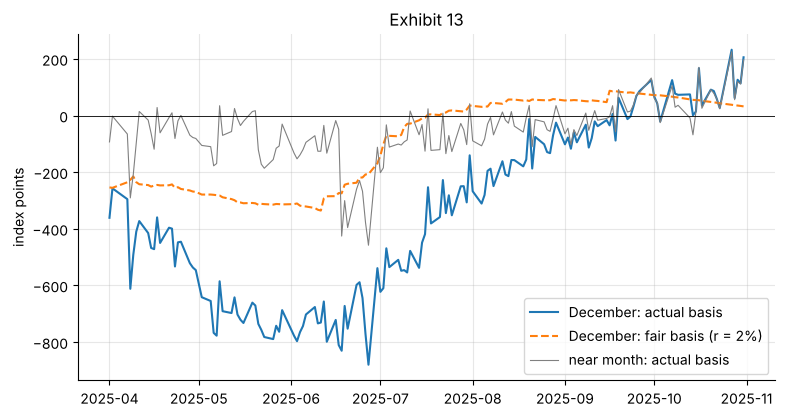

In [19]:
# December contract by month, and Exhibit 13
decm = d.filter(pl.col("c") == "202512")
print(decm.group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
          .agg(pl.col("basis").mean().round(1), pl.col("fair_basis").mean().round(1), pl.col("residual").mean().round(1),
               pl.col("r_implied").mean()).sort("month"))
fig, ax = plt.subplots()
x = decm["date"].str.to_date()
ax.plot(x, decm["basis"], label="December: actual basis"); ax.plot(x, decm["fair_basis"], "--", label="December: fair basis (r = 2%)")
ax.plot(near["date"].str.to_date(), near["basis"], color="grey", lw=0.8, label="near month: actual basis")
ax.axhline(0, color="black", lw=0.6); ax.set_ylabel("index points"); ax.set_title("Exhibit 13"); ax.legend(); plt.show()

2025-04-01 [('202504', 15, -93.17), ('202505', 50, -77.17), ('202506', 78, -94.17), ('202509', 169, -357.17), ('202512', 260, -361.17), ('202603', 351, -347.17)]
2025-06-27 [('202507', 19, -458.08), ('202508', 54, -632.08), ('202509', 82, -746.08), ('202512', 173, -880.08), ('202603', 264, -973.08), ('202606', 355, -1087.08)]
2025-10-31 [('202511', 19, 196.65), ('202512', 47, 205.65), ('202601', 82, 236.65), ('202603', 138, 242.65), ('202606', 229, 216.65), ('202609', 320, -21.35)]


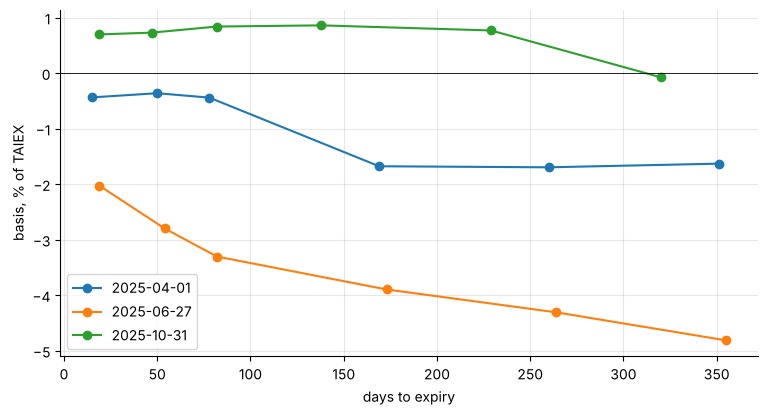

shape: (2, 4)
┌────────────┬────────────┬────────────┬───────────┐
│ date       ┆ S          ┆ F          ┆ basis     │
│ ---        ┆ ---        ┆ ---        ┆ ---       │
│ str        ┆ f64        ┆ f64        ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╡
│ 2025-06-27 ┆ 22580.0800 ┆ 22122.0000 ┆ -458.0800 │
│ 2025-06-30 ┆ 22256.0200 ┆ 22144.0000 ┆ -112.0200 │
└────────────┴────────────┴────────────┴───────────┘
shape: (4, 6)
┌────────────┬────────────┬────────────┬────────────┬────────────┬───────────┐
│ date       ┆ open       ┆ max        ┆ min        ┆ close      ┆ spread    │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---       │
│ str        ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64       │
╞════════════╪════════════╪════════════╪════════════╪════════════╪═══════════╡
│ 2025-06-26 ┆ 22425.3900 ┆ 22587.6700 ┆ 22391.2700 ┆ 22492.3400 ┆ 61.7300   │
│ 2025-06-27 ┆ 22503.8500 ┆ 22580.0800 ┆ 22388.5900 ┆ 22580.0800 ┆ 87.7400

In [20]:
# Exhibit 14: three term structures; and the pitfall numbers
fig, ax = plt.subplots()
for day in ("2025-04-01", "2025-06-27", "2025-10-31"):
    cv = d.filter(pl.col("date") == pl.lit(day))
    ax.plot(cv["days"], cv["basis"] / cv["S"] * 100, marker="o", label=day)
    print(day, cv.select("c", "days", pl.col("basis").round(2)).rows())
ax.axhline(0, color="black", lw=0.6); ax.set_xlabel("days to expiry"); ax.set_ylabel("basis, % of TAIEX"); ax.legend(); plt.show()
j = d.filter(pl.col("c") == "202507").filter(pl.col("date").is_in(["2025-06-27", "2025-06-30"]))
print(j.select("date", "S", "F", "basis"))
print(pl.read_csv(DATA / "TAIEX_OHLC__2025-06-26__2025-07-01.csv"))
print(near.with_columns((pl.col("qtau_imp") / pl.col("tau")).alias("q_ann")).sort("q_ann", descending=True).head(1).select("date", "days", "basis", "q_ann"))

In [21]:
# Example 10: the December contract on 27 June 2025, and the sensitivity of the implied yield to r
x = snap.filter(pl.col("c") == "202512").row(0, named=True)
print(f"tau {x['tau']:.5f}  qtau {x['qtau_imp']:.2%}  annual {x['qtau_imp']/x['tau']:.2%}  PV of dividends {x['S'] - x['F']*math.exp(-R_PROXY*x['tau']):.1f} points")
print(f"F* {x['S'] + x['fair_basis']:.2f}  residual {x['residual']:.2f} ({x['residual']/x['S']:.2%})  implied financing rate {x['r_implied']:.2%}")
pl.DataFrame({"r": [0.0, 0.01, 0.02, 0.03]}).with_columns(
    (pl.col("r") * x["tau"] - math.log(x["F"] / x["S"])).alias("implied qtau"),
    (x["F"] - x["S"] * (pl.col("r") * x["tau"] - x["qtau_real"]).exp()).alias("residual"))

tau 0.47397  qtau 4.92%  annual 10.39%  PV of dividends 1084.8 points
F* 22372.90  residual -672.90 (-2.98%)  implied financing rate -4.44%


r,implied qtau,residual
f64,f64,f64
0.0000,0.0398,-461.8199
0.0100,0.0445,-567.1102
0.0200,0.0492,-672.9007
0.0300,0.0540,-779.1939


## Part 7 — Practice problems (computational) and an extension

In [22]:
print("PP2 ", f"{annuity_fv(5000, 0.0015, 120):,.2f}", f"{annuity_pv(5000, 0.0015, 120):,.2f}")
print("PP3 ", f"due {annuity_pv(2000, 0.025, 15, True):,.2f}  ordinary {annuity_pv(2000, 0.025, 15):,.2f}")
print("PP4 ", f"{-math.log(1 - 6_000_000*0.002/40_000)/math.log(1.002):.2f} months")
print("PP6 ", f"g {(0.08*80 - 3.2)/(80 + 3.2):.3%}  k {3.2*1.04/80 + 0.04:.2%}")
dv = [2.0 * 1.1**t for t in (1, 2, 3)]
print("PP8 ", f"{sum(x / 1.08**t for t, x in enumerate(dv, 1)) + dv[-1]*1.03/0.05/1.08**3:.2f}")
print("PP9 ", f"{bond_price(0.0175, 0.0125, 7):.4f}")
lg10 = []; y10, _ = bisect(lambda y: bond_price(y, 0.02, 3) - 98.0, 0.02, 0.04, tol=1e-9, log=lg10)
print("PP10", [(f"{m:.2%}", round(f, 4)) for _, _, _, m, f in lg10[:3]], f"YTM {y10:.4%}")
s11 = schedule(8_000_000, 0.021, 20); A11 = s11["payment"][0]
print("PP11", f"{A11:,.2f}", f"{s11['balance'][95]:,.2f}", f"{s11['interest'][96]:,.2f}", f"{s11['principal'][96]:,.2f}")
s12 = schedule(8_000_000, 0.021, 20, method="equal")
print("PP12", f"{s12['payment'][0]:,.2f}", f"{s12['payment'][-1]:,.2f}", f"{s12['interest'].sum():,.2f}", f"vs {s11['interest'].sum():,.2f}")
print("PP13", f"{1.019**2/1.016 - 1:.4%}")
print("PP14", f"{31.20*(1 + 0.015*0.25)/(1 + 0.042*0.25):.4f}")
Ff = 23_000 * math.exp(0.02*0.2 - 0.012)
print("PP15", f"fair {Ff:.2f}  qtau {0.004 - math.log(22_600/23_000):.4%}  residual {22_600 - Ff:.2f}  r_impl {(0.012 + math.log(22_600/23_000))/0.2:.2%}")

PP2  656,853.04 548,723.77
PP3  due 25,381.82  ordinary 24,762.76
PP4  178.52 months
PP6  g 3.846%  k 8.16%
PP8  49.76
PP9  96.7327
PP10 [('3.00%', -0.8286), ('2.50%', 0.572), ('2.75%', -0.1317)] YTM 2.7030%
PP11 40,850.63 5,195,828.36 9,092.70 31,757.93
PP12 47,333.33 33,391.67 1,687,000.00 vs 1,804,151.78
PP13 2.2009%
PP14 30.9916
PP15 fair 22816.73  qtau 2.1544%  residual -216.73  r_impl -2.77%


In [23]:
# PP16: the September 2025 contract by month
(d.filter(pl.col("c") == "202509")
  .group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
  .agg(pl.len().alias("n"), *[pl.col(x).mean().round(0) for x in ("basis", "carry", "dividends", "residual")], pl.col("r_implied").mean())
  .sort("month"))

month,n,basis,carry,dividends,residual,r_implied
i32,u32,f64,f64,f64,f64,f64
4,20,-439.0000,165.0000,478.0000,-126.0000,0.0038
5,20,-637.0000,145.0000,516.0000,-266.0000,-0.0178
6,21,-619.0000,113.0000,459.0000,-273.0000,-0.0298
7,23,-253.0000,79.0000,178.0000,-154.0000,-0.0174
8,21,-73.0000,42.0000,74.0000,-41.0000,0.0044
9,12,-34.0000,12.0000,40.0000,-6.0000,0.0309


### Extension: was 2025 unusual?

Repeat Part 6 for the 2024 dividend season. Fetch `TaiwanFuturesDaily` (TX, regular session `trading_session == "position"`), `TaiwanStockPrice` (TAIEX) and `TaiwanStockTotalReturnIndex` (TAIEX) for April–December 2024, rebuild Exhibits 11–13, and compare the residuals. A residual that is negative every summer would point to a structural discount (weak reverse-arbitrage bound); one that appears only in 2025 would point to the hedging pressure after the April tariff shock. The helper below refreshes data with your own token (`FINMIND_TOKEN`); queries are limited in size, so it fetches month by month.

In [24]:
import os

def finmind(dataset, data_id, start, end):
    import requests
    out, d0 = [], dt.date.fromisoformat(start)
    while d0 <= dt.date.fromisoformat(end):
        d1 = min(dt.date(d0.year + (d0.month == 12), d0.month % 12 + 1, 1) - dt.timedelta(days=1), dt.date.fromisoformat(end))
        p = {"dataset": dataset, "data_id": data_id, "start_date": d0.isoformat(), "end_date": d1.isoformat(),
             "token": os.environ.get("FINMIND_TOKEN", "")}
        out.extend(requests.get("https://api.finmindtrade.com/api/v4/data", params=p, timeout=30).json().get("data", []))
        d0 = d1 + dt.timedelta(days=1)
    return pl.DataFrame(out)

# tx24 = finmind("TaiwanFuturesDaily", "TX", "2024-04-01", "2024-12-31").filter(pl.col("trading_session") == "position")   # uncomment to run